In [ ]:

# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

import pandas as pd
import zipfile
import io
import urllib.request

url = "https://archive.ics.uci.edu/static/public/357/occupancy+detection.zip"

# Download the original dataset from UCI
request = urllib.request.Request(
    url,
    headers={"User-Agent": "Mozilla/5.0"}
)

with urllib.request.urlopen(request, timeout=30) as response:
    zip_data = response.read()

# Read the original files from the ZIP archive
with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
    train_df = pd.read_csv(
        z.open("datatraining.txt"),
        sep=","
    )
    test_df = pd.read_csv(
        z.open("datatest.txt"),
        sep=","
    )
    test2_df = pd.read_csv(
        z.open("datatest2.txt"),
        sep=","
    )

print("Training data:", train_df.shape)
print("Test 1:", test_df.shape)
print("Test 2:", test2_df.shape)

display(train_df.head())

Training data: (8143, 7)
Test 1: (2665, 7)
Test 2: (9752, 7)


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 8143 entries, 1 to 8143
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           8143 non-null   datetime64[ns]
 1   Temperature    8143 non-null   float64       
 2   Humidity       8143 non-null   float64       
 3   Light          8143 non-null   float64       
 4   CO2            8143 non-null   float64       
 5   HumidityRatio  8143 non-null   float64       
 6   Occupancy      8143 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 508.9 KB

Missing values:
date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

Duplicate rows: 0

Occupancy distribution:
Occupancy
0    6414
1    1729
Name: count, dtype: int64

Occupancy percentages:
Occupancy
0    78.77
1    21.23
Name: proportion, dtype: floa

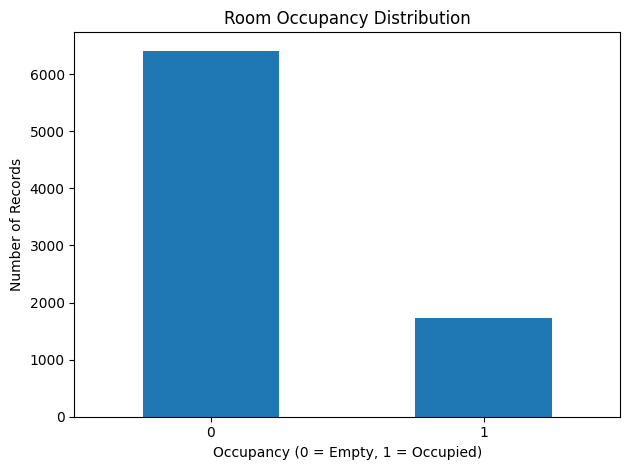

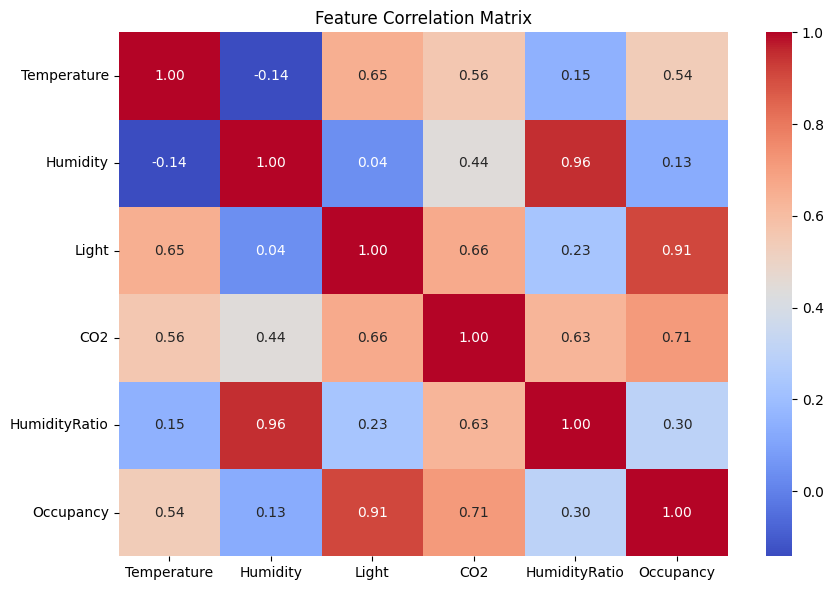

In [ ]:

# 4. Exploratory Data Analysis (EDA)

# Convert date column to datetime
for df in [train_df, test_df, test2_df]:
    df["date"] = pd.to_datetime(df["date"])

# Inspect the training data
print("Dataset information:")
train_df.info()

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nDuplicate rows:", train_df.duplicated().sum())

print("\nOccupancy distribution:")
print(train_df["Occupancy"].value_counts())

print("\nOccupancy percentages:")
print(
    (train_df["Occupancy"].value_counts(normalize=True) * 100)
    .round(2)
)

# Plot target distribution
train_df["Occupancy"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)
plt.title("Room Occupancy Distribution")
plt.xlabel("Occupancy (0 = Empty, 1 = Occupied)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Plot feature correlations
features = [
    "Temperature", "Humidity", "Light",
    "CO2", "HumidityRatio", "Occupancy"
]

plt.figure(figsize=(9, 6))
sns.heatmap(
    train_df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# الخصائص التي ستستخدمها النماذج للتنبؤ
feature_cols = [
    "Temperature",
    "Humidity",
    "Light",
    "CO2",
    "HumidityRatio"
]

# بيانات التدريب
X_train = train_df[feature_cols]
y_train = train_df["Occupancy"]

# مجموعتا الاختبار الأصليتان
X_test1 = test_df[feature_cols]
y_test1 = test_df["Occupancy"]

X_test2 = test2_df[feature_cols]
y_test2 = test2_df["Occupancy"]

# تعريف النماذج
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]),

    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            class_weight="balanced"
        ))
    ]),

    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])
}

# التدريب والتقييم
results = []
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    fitted_models[name] = model

    for test_name, X_eval, y_eval in [
        ("Test 1", X_test1, y_test1),
        ("Test 2", X_test2, y_test2)
    ]:
        predictions = model.predict(X_eval)

        results.append({
            "Model": name,
            "Test Set": test_name,
            "Accuracy": accuracy_score(y_eval, predictions),
            "Precision": precision_score(
                y_eval, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_eval, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_eval, predictions, zero_division=0
            )
        })

results_df = pd.DataFrame(results)

display(
    results_df.round(4).sort_values(
        ["Test Set", "F1-score"],
        ascending=[True, False]
    )
)

Training Random Forest...
Training SVM...
Training KNN...


,Model,Test Set,Accuracy,Precision,Recall,F1-score
2,SVM,Test 1,0.9700,0.9264,0.9969,0.9604
0,Random Forest,Test 1,0.9302,0.9426,0.8611,0.9000
4,KNN,Test 1,0.9197,0.9726,0.8025,0.8794
3,SVM,Test 2,0.9597,0.8410,0.9966,0.9122
1,Random Forest,Test 2,0.9525,0.8702,0.9097,0.8895
5,KNN,Test 2,0.9333,0.8317,0.8560,0.8437


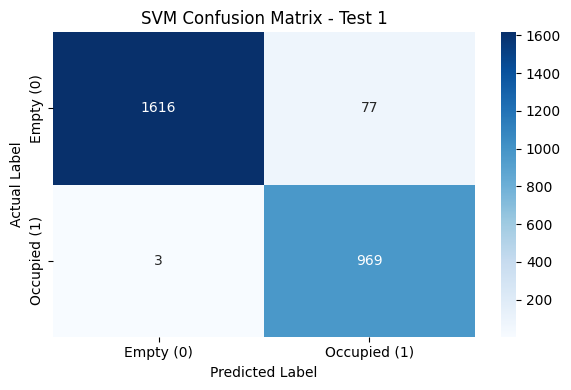


Classification Report - Test 1
              precision    recall  f1-score   support

       Empty     0.9981    0.9545    0.9758      1693
    Occupied     0.9264    0.9969    0.9604       972

    accuracy                         0.9700      2665
   macro avg     0.9623    0.9757    0.9681      2665
weighted avg     0.9720    0.9700    0.9702      2665



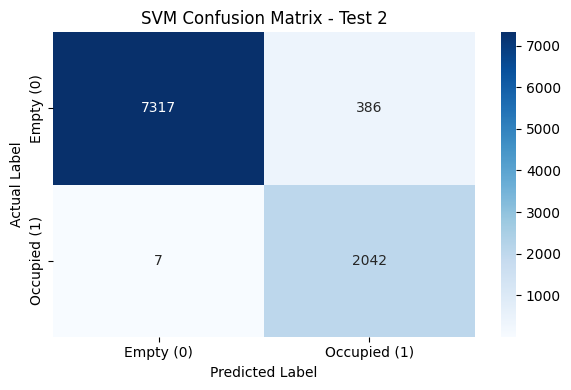


Classification Report - Test 2
              precision    recall  f1-score   support

       Empty     0.9990    0.9499    0.9738      7703
    Occupied     0.8410    0.9966    0.9122      2049

    accuracy                         0.9597      9752
   macro avg     0.9200    0.9732    0.9430      9752
weighted avg     0.9658    0.9597    0.9609      9752



In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# تحليل نموذج SVM على مجموعتي الاختبار
svm_model = fitted_models["SVM"]

test_sets = [
    ("Test 1", X_test1, y_test1),
    ("Test 2", X_test2, y_test2)
]

for test_name, X_eval, y_eval in test_sets:
    predictions = svm_model.predict(X_eval)

    cm = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1]
    )

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Empty (0)", "Occupied (1)"],
        yticklabels=["Empty (0)", "Occupied (1)"]
    )
    plt.title(f"SVM Confusion Matrix - {test_name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    print(f"\nClassification Report - {test_name}")
    print(classification_report(
        y_eval,
        predictions,
        target_names=["Empty", "Occupied"],
        digits=4,
        zero_division=0
    ))

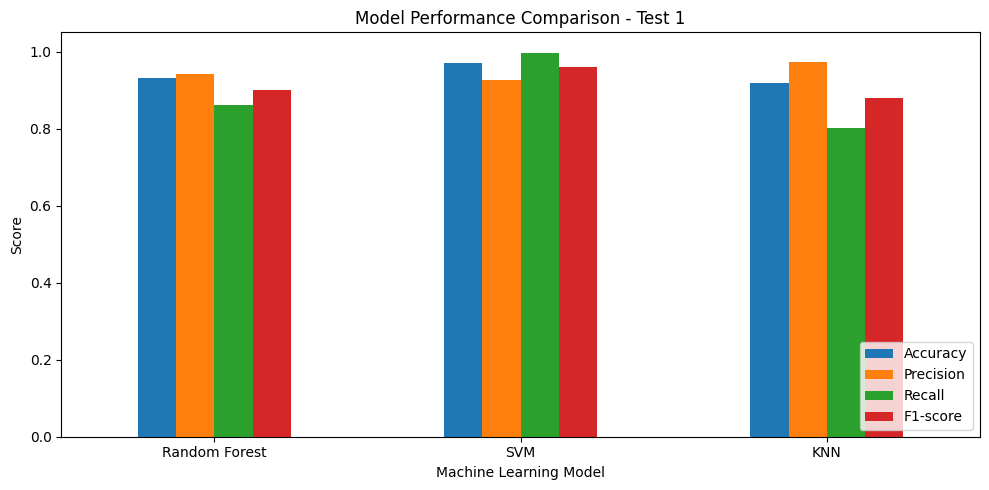

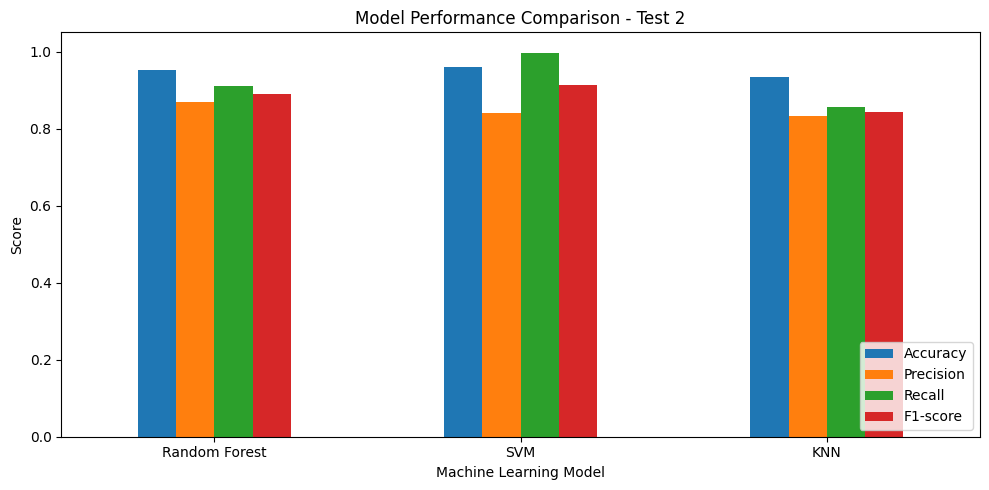

In [8]:

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

for test_name in ["Test 1", "Test 2"]:
    subset = results_df[results_df["Test Set"] == test_name]

    subset.plot(
        x="Model",
        y=metrics,
        kind="bar",
        figsize=(10, 5),
        ylim=(0, 1.05)
    )

    plt.title(f"Model Performance Comparison - {test_name}")
    plt.ylabel("Score")
    plt.xlabel("Machine Learning Model")
    plt.xticks(rotation=0)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


Test 1 - Confusion Matrix
[[1616   77]
 [   3  969]]


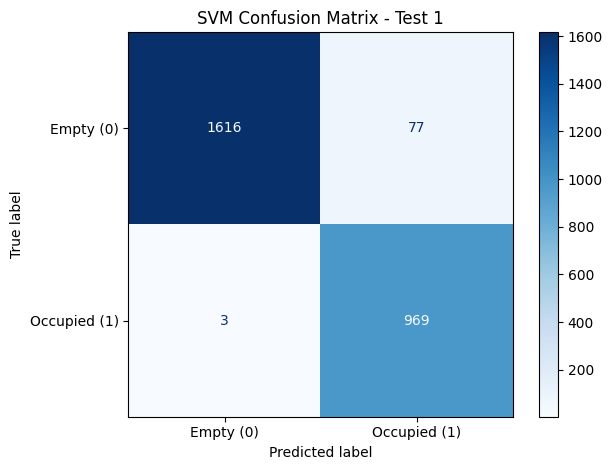


Test 2 - Confusion Matrix
[[7317  386]
 [   7 2042]]


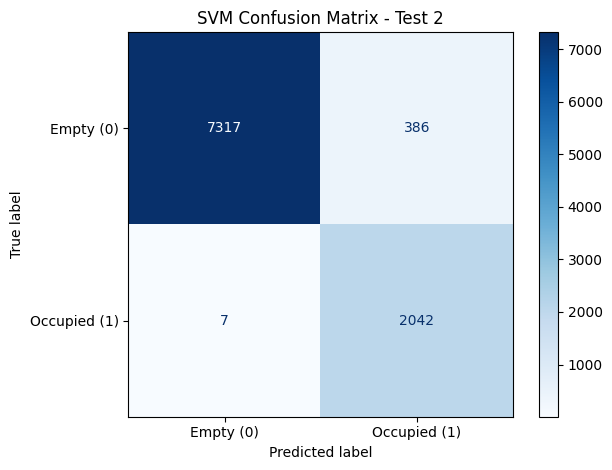

In [9]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

svm_model = fitted_models["SVM"]

for test_name, X_eval, y_eval in [
    ("Test 1", X_test1, y_test1),
    ("Test 2", X_test2, y_test2)
]:
    predictions = svm_model.predict(X_eval)

    cm = confusion_matrix(y_eval, predictions, labels=[0, 1])

    print(f"\n{test_name} - Confusion Matrix")
    print(cm)

    display_plot = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Empty (0)", "Occupied (1)"]
    )
    display_plot.plot(cmap="Blues", values_format="d")
    plt.title(f"SVM Confusion Matrix - {test_name}")
    plt.tight_layout()
    plt.savefig(
        f"svm_confusion_matrix_{test_name.lower().replace(' ', '_')}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()